# HCAHPS · Resultados por hospital, 2021–2024

Ejecuto las celdas en orden. En Colab: `Path("/content")` si hay archivos en el panel Archivos.

El año es el de medición. Por ejemplo, la publicación de noviembre de 2025 contiene resultados de enero a diciembre de 2024.

## 1.1 Normalizar los cuatro CSV

Cargo los campos usados en el análisis y armonizo sus encabezados. Los IDs se leen como texto para conservar sus ceros iniciales. Solo en las columnas de resultados, los textos de ausencia conocidos se leen como faltantes. La conversión numérica se hace aquí una sola vez: si aparece un texto inesperado, pandas avisa en lugar de tratarlo como faltante.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter

CARPETA = Path(r"C:\Users\conta\OneDrive\Escritorio\Estefania Thompson\Especialización Data\Proyecto final\HCAHPS")
ARCHIVOS = [
    "HCAHPS-Hospital_oct2022.csv",
    "HCAHPS-Hospital_nov2023.csv",
    "HCAHPS-Hospital_oct2024.csv",
    "HCAHPS-Hospital_nov2025.csv",
]

clave = ["Facility ID", "Start Date", "End Date"]
medida = "HCAHPS Measure ID"
descripcion = "HCAHPS Answer Description"
nota = "HCAHPS Answer Percent Footnote"
datos_hospital = ["Facility Name", "State", "City/Town"]
campos_valor = {
    "HCAHPS Answer Percent": "Porcentaje",
    "Patient Survey Star Rating": "Estrellas",
    "HCAHPS Linear Mean Value": "Puntuación media lineal",
}

def cargar_csv(nombre):
    campos = clave + datos_hospital + [medida, descripcion, nota, *campos_valor]
    datos = pd.read_csv(
        CARPETA / nombre,
        usecols=lambda campo: campo.strip() in campos or campo.strip() == "City",
        dtype="string",
        keep_default_na=False,
        na_values={campo: ["", "Not Available", "Not Applicable"] for campo in campos_valor},
    )
    datos = datos.rename(columns=str.strip).rename(columns={"City": "City/Town"})
    datos = datos[campos]
    for campo in ["Facility ID", medida, nota]:
        datos[campo] = datos[campo].str.strip()
    for campo in ["Start Date", "End Date"]:
        datos[campo] = pd.to_datetime(datos[campo], format="%m/%d/%Y")
    for campo in campos_valor:
        datos[campo] = pd.to_numeric(datos[campo])
    return datos.assign(Archivo=nombre)

archivos_normalizados = [cargar_csv(nombre) for nombre in ARCHIVOS]

## 1.2 Concatenar y validar

`hcahps` reúne los cuatro archivos en formato largo. Un hospital puede aparecer en muchas filas. La combinación que debe ser única es **hospital + fechas del periodo + código HCAHPS**, porque define una celda del pivot.

In [2]:
hcahps = pd.concat(archivos_normalizados, ignore_index=True)
del archivos_normalizados

if hcahps[["Facility ID", medida]].eq("").any().any() or hcahps[clave].isna().any().any():
    raise ValueError("Hay filas sin hospital, indicador o fechas.")
if hcahps["Start Date"].gt(hcahps["End Date"]).any():
    raise ValueError("Hay periodos cuya fecha de inicio es posterior a la de fin.")
if hcahps.duplicated(clave + [medida]).any():
    raise ValueError("Hay más de un resultado para el mismo hospital, periodo e indicador.")

display(hcahps.groupby(["Start Date", "End Date", "Archivo"], as_index=False).agg(
    hospitales=("Facility ID", "nunique"), filas=(medida, "size"),
))

,Start Date,End Date,Archivo,hospitales,filas
0,2021-01-01,2021-12-31,HCAHPS-Hospital_oct2022.csv,4845,450585
1,2022-01-01,2022-12-31,HCAHPS-Hospital_nov2023.csv,4829,449097
2,2023-01-01,2023-12-31,HCAHPS-Hospital_oct2024.csv,4779,444447
3,2024-01-01,2024-12-31,HCAHPS-Hospital_nov2025.csv,4791,445563


## 1.3 Pasar los indicadores a columnas

Cada medida toma su resultado de la columna que le corresponde: porcentaje, estrellas o puntuación media lineal. El pivot conserva el valor publicado sin agregarlo. `tabla_hospitales` tiene una fila por **hospital y periodo**. `Periodo` es un intervalo inclusivo de fechas de pandas.

La proyección de datos del hospital reúne nombre, estado y ciudad una sola vez por periodo. En el CSV largo esos datos se repiten por cada indicador.

In [3]:
hcahps["Origen"] = (
    pd.Series("HCAHPS Answer Percent", index=hcahps.index)
    .mask(hcahps[medida].str.endswith("STAR_RATING"), "Patient Survey Star Rating")
    .mask(hcahps[medida].str.endswith("LINEAR_SCORE"), "HCAHPS Linear Mean Value")
)
hcahps["Valor"] = pd.Series(pd.NA, index=hcahps.index, dtype="Float64")
for campo in campos_valor:
    corresponde = hcahps["Origen"].eq(campo)
    if hcahps.loc[~corresponde, campo].notna().any():
        raise ValueError(f"Hay resultados en {campo} para códigos asignados a otra unidad.")
    hcahps.loc[corresponde, "Valor"] = hcahps.loc[corresponde, campo]

tabla_hospitales = (
    hcahps[clave + datos_hospital].drop_duplicates()
    .merge(
        hcahps.pivot(index=clave, columns=medida, values="Valor").rename_axis(columns=None),
        on=clave, validate="one_to_one",
    )
)
tabla_hospitales.insert(4, "Periodo", pd.IntervalIndex.from_arrays(
    tabla_hospitales.pop("Start Date"), tabla_hospitales.pop("End Date"), closed="both",
))
print(f"{len(tabla_hospitales):,} filas de hospital y periodo · "
      f"{tabla_hospitales.shape[1] - 5} indicadores")

19,244 filas de hospital y periodo · 93 indicadores


### Catálogo y vista de ejemplo

Busco el código en `catalogo` y lo uso directamente como nombre de columna de `tabla_hospitales`. La descripción original y la unidad están en el catálogo. En la vista breve puedo aplicar etiquetas más fáciles de leer.

In [4]:
catalogo = (
    hcahps[[medida, descripcion, "Origen"]].drop_duplicates()
    .assign(Unidad=lambda df: df["Origen"].map(campos_valor))
    .drop(columns="Origen")
    .sort_values(medida, ignore_index=True)
)
display(catalogo)

,HCAHPS Measure ID,HCAHPS Answer Description,Unidad
0,H_BATH_HELP_A_P,"Patients ""always"" received bathroom help as so...",Porcentaje
1,H_BATH_HELP_SN_P,"Patients ""sometimes"" or ""never"" received bathr...",Porcentaje
2,H_BATH_HELP_U_P,"Patients ""usually"" received bathroom help as s...",Porcentaje
3,H_CALL_BUTTON_A_P,"Patients ""always"" received call button help as...",Porcentaje
4,H_CALL_BUTTON_SN_P,"Patients ""sometimes"" or ""never"" received call ...",Porcentaje
...,...,...,...
88,H_SIDE_EFFECTS_SN_P,"Staff ""sometimes"" or ""never"" explained possibl...",Porcentaje
89,H_SIDE_EFFECTS_U_P,"Staff ""usually"" explained possible side effects",Porcentaje
90,H_STAR_RATING,Summary star rating,Estrellas
91,H_SYMPTOMS_N_P,"No, staff ""did not"" give patients information ...",Porcentaje


In [5]:
catalogo.loc[catalogo[medida].str.contains("COMP")]

,HCAHPS Measure ID,HCAHPS Answer Description,Unidad
11,H_COMP_1_A_P,"Nurses ""always"" communicated well",Porcentaje
12,H_COMP_1_LINEAR_SCORE,Nurse communication - linear mean score,Puntuación media lineal
13,H_COMP_1_SN_P,"Nurses ""sometimes"" or ""never"" communicated well",Porcentaje
14,H_COMP_1_STAR_RATING,Nurse communication - star rating,Estrellas
15,H_COMP_1_U_P,"Nurses ""usually"" communicated well",Porcentaje
16,H_COMP_2_A_P,"Doctors ""always"" communicated well",Porcentaje
17,H_COMP_2_LINEAR_SCORE,Doctor communication - linear mean score,Puntuación media lineal
18,H_COMP_2_SN_P,"Doctors ""sometimes"" or ""never"" communicated well",Porcentaje
19,H_COMP_2_STAR_RATING,Doctor communication - star rating,Estrellas
20,H_COMP_2_U_P,"Doctors ""usually"" communicated well",Porcentaje


Ejemplo de muestra: hospitales con ID: 010001 y algunas de sus puntuaciones en todos los periodos.

In [6]:
display(
    tabla_hospitales.loc[
        tabla_hospitales["Facility ID"].eq("010001"),
        ["Facility Name", "Periodo", "H_COMP_1_A_P", "H_COMP_1_U_P",
         "H_COMP_1_SN_P", "H_COMP_2_A_P", "H_COMP_3_A_P", "H_HSP_RATING_9_10"],
    ]
    .sort_values("Periodo")
    .rename(columns={
        "H_COMP_1_A_P": "Buena comunicación con enfermería -Siempre (%)",
        "H_COMP_1_U_P": "Buena comunicación con enfermería -Normalmente (%)",
        "H_COMP_1_SN_P": "Buena comunicación con enfermería -A veces o nunca (%)",
        "H_COMP_2_A_P": "Buena comunicación con médicos -Siempre (%)",
        "H_COMP_3_A_P": "Ayuda a tiempo -Siempre (%)",
        "H_HSP_RATING_9_10": "Valoración general -9 o 10 (%)",
    })
)

,Facility Name,Periodo,Buena comunicación con enfermería -Siempre (%),Buena comunicación con enfermería -Normalmente (%),Buena comunicación con enfermería -A veces o nunca (%),Buena comunicación con médicos -Siempre (%),Ayuda a tiempo -Siempre (%),Valoración general -9 o 10 (%)
0,SOUTHEAST HEALTH MEDICAL CENTER,"[2021-01-01 00:00:00, 2021-12-31 00:00:00]",77.0,16.0,7.0,79.0,60.0,73.0
4845,SOUTHEAST HEALTH MEDICAL CENTER,"[2022-01-01 00:00:00, 2022-12-31 00:00:00]",74.0,18.0,8.0,78.0,56.0,70.0
9674,SOUTHEAST HEALTH MEDICAL CENTER,"[2023-01-01 00:00:00, 2023-12-31 00:00:00]",72.0,22.0,6.0,78.0,59.0,71.0
14453,SOUTHEAST HEALTH MEDICAL CENTER,"[2024-01-01 00:00:00, 2024-12-31 00:00:00]",75.0,19.0,6.0,81.0,60.0,75.0


## 2. Consultar las notas CMS

`auditoria_notas` deja un código por fila para facilitar los filtros. Por ejemplo, la nota original `10, 11` se divide en los códigos 10 y 11. Se muestra el significado de los códigos presentes.

[Diccionario de CMS, apéndice E](https://data.cms.gov/provider-data/sites/default/files/data_dictionaries/hospital/HOSPITAL_Data_Dictionary.pdf)

In [7]:
glosario_notas = {
    "1": "Casos o pacientes insuficientes para publicar.",
    "3": "Datos de un periodo más corto del requerido.",
    "5": "Resultado no disponible para el periodo.",
    "6": "Menos de 100 pacientes completaron la encuesta.",
    "10": "Resultado basado en menos de 50 encuestas completadas.",
    "11": "Discrepancias en el proceso de recogida de datos.",
    "19": "El centro no participa en los programas de reporte indicados por CMS.",
    "24": "Resultados combinados con el hospital administrativo de VA.",
    "28": "Excepción por circunstancias extraordinarias; el resultado puede verse afectado.",
    "29": "Periodo parcial por una excepción aprobada por CMS.",
}


auditoria_notas = (
    hcahps.loc[hcahps[nota].ne(""), [*clave, medida, nota]]
    .assign(**{"Código nota": lambda df: df[nota].str.split(",")})
    .explode("Código nota", ignore_index=True)
)
auditoria_notas["Código nota"] = auditoria_notas["Código nota"].str.strip()

display(
    auditoria_notas[["Código nota"]].drop_duplicates().sort_values("Código nota")
    .assign(Significado=lambda df: df["Código nota"].map(glosario_notas)
            .fillna("Consultar el diccionario CMS de la publicación"))
    .reset_index(drop=True)
)

,Código nota,Significado
0,1,Casos o pacientes insuficientes para publicar.
1,10,Resultado basado en menos de 50 encuestas comp...
2,11,Discrepancias en el proceso de recogida de datos.
3,19,El centro no participa en los programas de rep...
4,24,Resultados combinados con el hospital administ...
5,28,Excepción por circunstancias extraordinarias; ...
6,29,Periodo parcial por una excepción aprobada por...
7,3,Datos de un periodo más corto del requerido.
8,5,Resultado no disponible para el periodo.
9,6,Menos de 100 pacientes completaron la encuesta.


## 3. Comparar hospitales de un estado

El ejemplo muestra los diez porcentajes publicados más altos de buena comunicación con enfermería en Alabama durante 2024. Se lee del formato largo, donde el resultado y la nota CMS ya están en la misma fila. La marca de muestra pequeña se basa en las notas 6 o 10 y se conserva el resultado publicado. En los empates se conserva el orden del CSV.

In [8]:
periodo_alabama = pd.Interval(pd.Timestamp("2024-01-01"), pd.Timestamp("2024-12-31"), closed="both")

display(
    hcahps.loc[
        hcahps["State"].eq("AL")
        & hcahps[medida].eq("H_COMP_1_A_P")
        & hcahps["Start Date"].eq(periodo_alabama.left)
        & hcahps["End Date"].eq(periodo_alabama.right),
        ["Facility ID", "Facility Name", "State", "Valor", nota],
    ]
    .dropna(subset="Valor")
    .sort_values("Valor", ascending=False, kind="stable")
    .head(30)
    .assign(
        Periodo=periodo_alabama,
        **{"Muestra pequeña": lambda df: df[nota]
           .str.contains(r"(?:^|,)\s*(?:6|10)\s*(?:,|$)", na=False)
           .map({True: "Sí", False: ""})},
    )
    [["Facility ID", "Facility Name", "State", "Periodo", "Valor", nota, "Muestra pequeña"]]
    .rename(columns={"Valor": "Buena com. Enfermería · Siempre (%)", nota: "Notas CMS"})
)

,Facility ID,Facility Name,State,Periodo,Buena com. Enfermería · Siempre (%),Notas CMS,Muestra pequeña
1352034,011304,OCHSNER CHOCTAW GENERAL,AL,"[2024-01-01 00:00:00, 2024-12-31 00:00:00]",95.0,10,Sí
1351941,011302,RED BAY HOSPITAL,AL,"[2024-01-01 00:00:00, 2024-12-31 00:00:00]",94.0,6,Sí
1346082,010044,MARION REGIONAL MEDICAL CENTER,AL,"[2024-01-01 00:00:00, 2024-12-31 00:00:00]",93.0,6,Sí
1344501,010008,CRENSHAW COMMUNITY HOSPITAL,AL,"[2024-01-01 00:00:00, 2024-12-31 00:00:00]",90.0,10,Sí
1346175,010045,FAYETTE MEDICAL CENTER,AL,"[2024-01-01 00:00:00, 2024-12-31 00:00:00]",87.0,,
1347291,010073,CLAY COUNTY HOSPITAL,AL,"[2024-01-01 00:00:00, 2024-12-31 00:00:00]",87.0,10,Sí
1348686,010101,CITIZENS BAPTIST MEDICAL CENTER,AL,"[2024-01-01 00:00:00, 2024-12-31 00:00:00]",87.0,,
1351197,010168,JACK HUGHSTON MEMORIAL HOSPITAL,AL,"[2024-01-01 00:00:00, 2024-12-31 00:00:00]",87.0,,
1344873,010018,CALLAHAN EYE HOSPITAL,AL,"[2024-01-01 00:00:00, 2024-12-31 00:00:00]",86.0,10,Sí
1345152,010022,FLOYD CHEROKEE MEDICAL CENTER,AL,"[2024-01-01 00:00:00, 2024-12-31 00:00:00]",86.0,10,Sí


**Valor numérico con nota 6 o 10:**	"Muestra pequeña" - CMS advierte que esos resultados se basan en menos de 100 o menos de 50 encuestas completadas, respectivamente.

**Valor numérico con nota 3 o 29:**	"Periodo parcial" - Aunque el archivo muestre las mismas fechas para todos, ese resultado se calculó con una ventana efectiva más corta.

**Valor numérico con nota 11:**	Hubo "discrepancias" en la recogida de datos - Si ese hospital destaca mucho en el gráfico, lo menciono en la nota al interpretar el resultado.

**Sin valor numérico:**	"Dato faltante" - Si hago un resumen por ciudad, indico cuántos hospitales sí tenían un valor para ese indicador.

## 4. Visualizaciones

Selecciono un año para los rankings y el gráfico de estrellas. Los rankings muestran los cinco porcentajes más altos de cada respuesta. El interruptor de muestra pequeña afecta a los rankings de porcentajes. Si es desactivado, los resultados incluidos con notas 6 o 10 llevan un asterisco.

In [9]:
nombres_estados = {
    "AL": "Alabama", "AK": "Alaska", "AZ": "Arizona", "AR": "Arkansas",
    "CA": "California", "CO": "Colorado", "CT": "Connecticut", "DE": "Delaware",
    "FL": "Florida", "GA": "Georgia", "HI": "Hawaii", "ID": "Idaho",
    "IL": "Illinois", "IN": "Indiana", "IA": "Iowa", "KS": "Kansas",
    "KY": "Kentucky", "LA": "Louisiana", "ME": "Maine", "MD": "Maryland",
    "MA": "Massachusetts", "MI": "Michigan", "MN": "Minnesota", "MS": "Mississippi",
    "MO": "Missouri", "MT": "Montana", "NE": "Nebraska", "NV": "Nevada",
    "NH": "New Hampshire", "NJ": "New Jersey", "NM": "New Mexico", "NY": "New York",
    "NC": "North Carolina", "ND": "North Dakota", "OH": "Ohio", "OK": "Oklahoma",
    "OR": "Oregon", "PA": "Pennsylvania", "RI": "Rhode Island", "SC": "South Carolina",
    "SD": "South Dakota", "TN": "Tennessee", "TX": "Texas", "UT": "Utah",
    "VT": "Vermont", "VA": "Virginia", "WA": "Washington", "WV": "West Virginia",
    "WI": "Wisconsin", "WY": "Wyoming", "DC": "District of Columbia",
    "AS": "American Samoa", "GU": "Guam", "MP": "Northern Mariana Islands",
    "PR": "Puerto Rico", "VI": "U.S. Virgin Islands",
}

In [10]:
anio = 2021
excluir_muestra_pequena = True  # Cambia a False para incluir resultados con notas 6 o 10.
periodo_grafico = pd.Interval(
    pd.Timestamp(f"{anio}-01-01"), pd.Timestamp(f"{anio}-12-31"), closed="both",
)

hospitales_anio = tabla_hospitales.loc[
    tabla_hospitales["Periodo"].eq(periodo_grafico)
].copy()

notas_muestra = auditoria_notas.loc[
    auditoria_notas["Start Date"].eq(periodo_grafico.left)
    & auditoria_notas["End Date"].eq(periodo_grafico.right)
    & auditoria_notas["Código nota"].isin(["6", "10"])
]

# Si activas el filtro, aparta solo el resultado afectado por la nota.
if excluir_muestra_pequena:
    for codigo, filas in notas_muestra.groupby("HCAHPS Measure ID"):
        hospitales_anio.loc[
            hospitales_anio["Facility ID"].isin(filas["Facility ID"]), codigo
        ] = pd.NA

def graficar_extremos(codigos, titulos, tema, n=5):
    fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5), layout="constrained")
    hay_marca = False

    for ax, codigo, titulo in zip(ejes, codigos, titulos):
        top = (
            hospitales_anio[["Facility ID", "Facility Name", "State", codigo]]
            .dropna(subset=[codigo])
            .sort_values([codigo, "Facility Name", "Facility ID"],
                         ascending=[False, True, True])
            .head(n)
        )
        ids_con_nota = notas_muestra.loc[
            notas_muestra["HCAHPS Measure ID"].eq(codigo), "Facility ID"
        ]
        muestra_pequena = top["Facility ID"].isin(ids_con_nota)
        hay_marca = hay_marca or muestra_pequena.any()
        estado_completo = top["State"].map(nombres_estados).fillna(top["State"])
        etiquetas = (
            top["Facility Name"] + " (" + estado_completo + ")"
            + muestra_pequena.map({True: " *", False: ""})
        )

        barras = ax.barh(range(len(top)), top[codigo].astype(float), color="#176B73")
        ax.set_yticks(range(len(top)), etiquetas)
        ax.invert_yaxis()
        ax.bar_label(barras, fmt="%.0f%%", padding=3)
        ax.set(xlim=(0, 108), xticks=range(0, 101, 20), xlabel="Porcentaje publicado",
               title=f"Top {n} · {titulo}")
        ax.xaxis.set_major_formatter(PercentFormatter(100))

    titulo_figura = f"{tema} · {anio}"
    if hay_marca:
        titulo_figura += "\n* Nota CMS 6 o 10 · muestra pequeña"
    if excluir_muestra_pequena:
        titulo_figura += "\nExcluye resultados con notas CMS 6 o 10"
    fig.suptitle(titulo_figura)
    plt.show()

### 1. ¿Qué hospitales tienen los porcentajes más altos en cada extremo de la comunicación con enfermería?

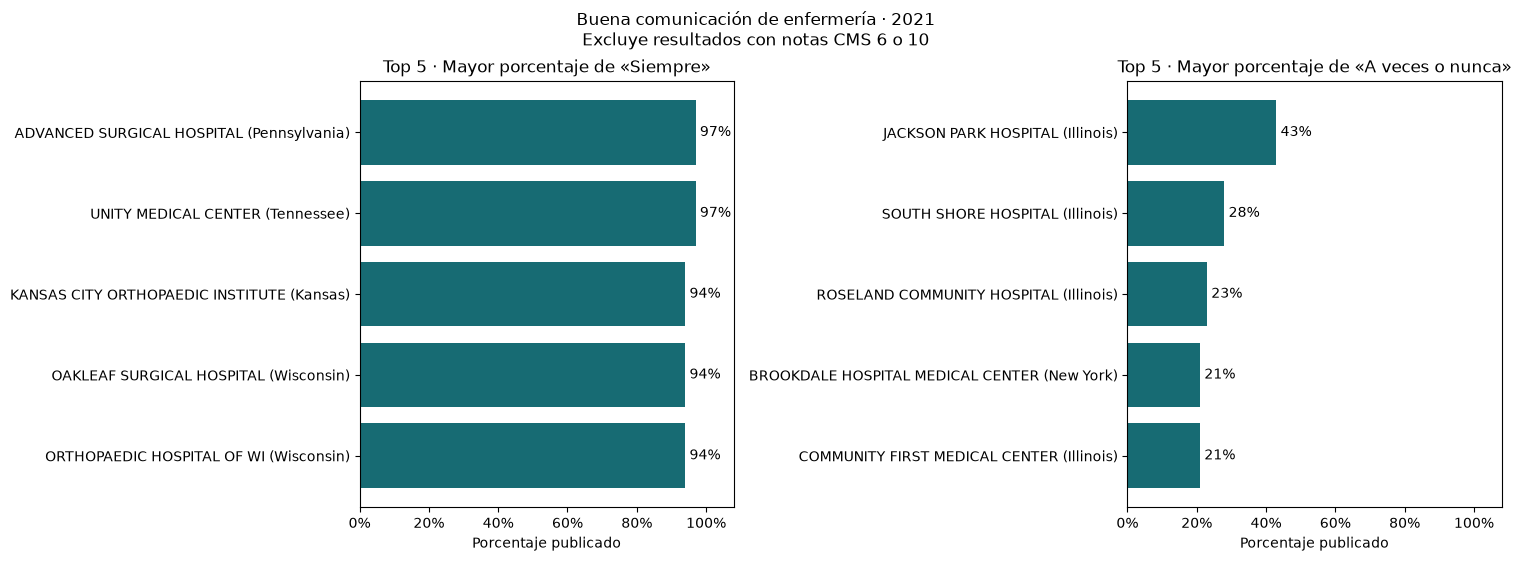

In [11]:
graficar_extremos(
    ["H_COMP_1_A_P", "H_COMP_1_SN_P"],
    ["Mayor porcentaje de «Siempre»", "Mayor porcentaje de «A veces o nunca»"],
    "Buena comunicación de enfermería",
)

#### a) Extremos de la buena comunicación de enfermería en todos los años (2021-2024)

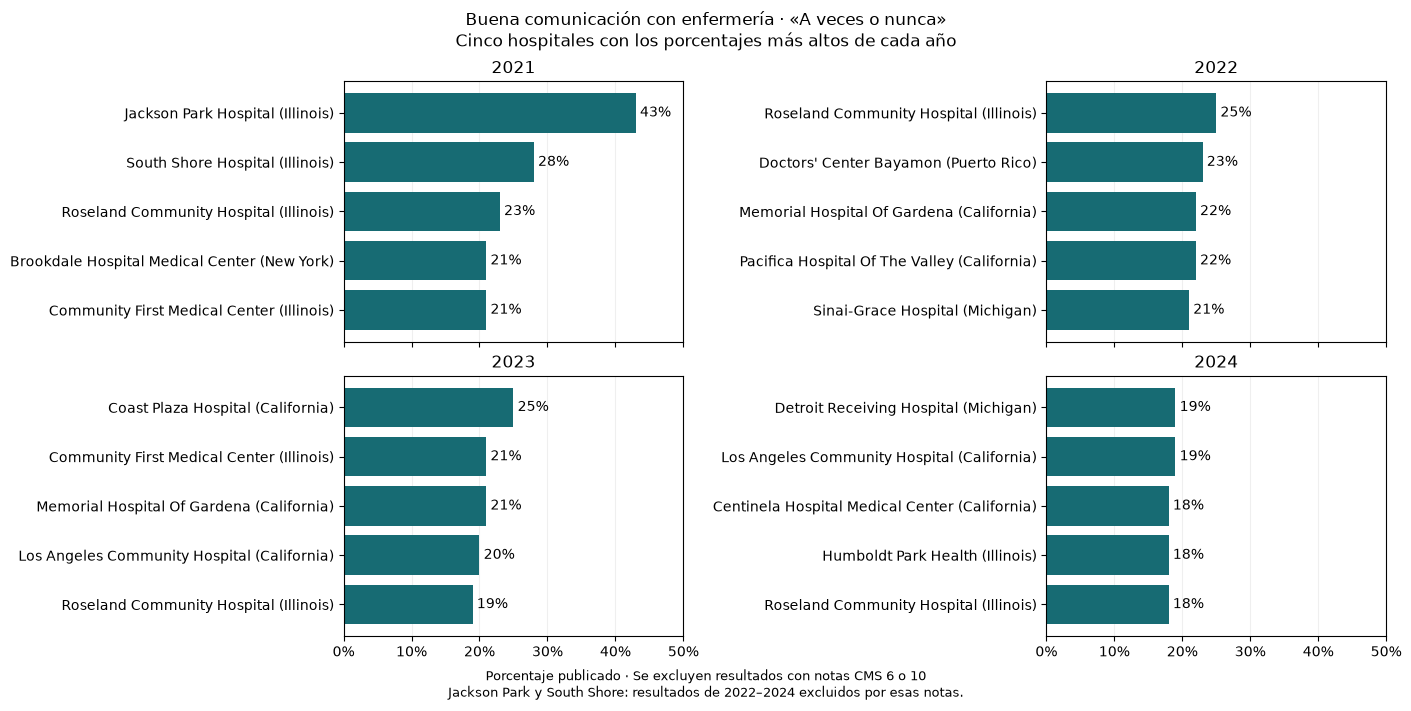

In [13]:
anios = [2021, 2022, 2023, 2024]

top_anual = (
    hcahps.loc[
        hcahps["HCAHPS Measure ID"].eq("H_COMP_1_SN_P")
        & hcahps["Start Date"].dt.year.isin(anios)
        & ~hcahps["HCAHPS Answer Percent Footnote"].str.contains(
            r"(?:^|,)\s*(?:6|10)\s*(?:,|$)", na=False
        ),
        ["Facility ID", "Facility Name", "State", "Start Date", "Valor"],
    ]
    .dropna(subset=["Valor"])
    .assign(Anio=lambda df: df["Start Date"].dt.year)
    .sort_values(["Valor", "Facility Name", "Facility ID"],
                 ascending=[False, True, True])
    .groupby("Anio").head(5)
)

fig, ejes = plt.subplots(2, 2, figsize=(14, 7), sharex=True, layout="constrained")

for ax, anio_panel in zip(ejes.flat, anios):
    top = top_anual.loc[top_anual["Anio"].eq(anio_panel)]
    estados = top["State"].map(nombres_estados).fillna(top["State"])
    etiquetas = top["Facility Name"].str.title() + " (" + estados + ")"

    barras = ax.barh(range(len(top)), top["Valor"].astype(float), color="#176B73")
    ax.set_yticks(range(len(top)), etiquetas)
    ax.invert_yaxis()
    ax.bar_label(barras, fmt="%.0f%%", padding=3)
    ax.set(title=str(anio_panel), xlim=(0, 50))
    ax.xaxis.set_major_formatter(PercentFormatter(100))
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    "Buena comunicación con enfermería · «A veces o nunca»\n"
    "Cinco hospitales con los porcentajes más altos de cada año"
)
fig.supxlabel(
    "Porcentaje publicado · Se excluyen resultados con notas CMS 6 o 10\n"
    "Jackson Park y South Shore: resultados de 2022–2024 excluidos por esas notas.",
    fontsize=9,
)
plt.show()

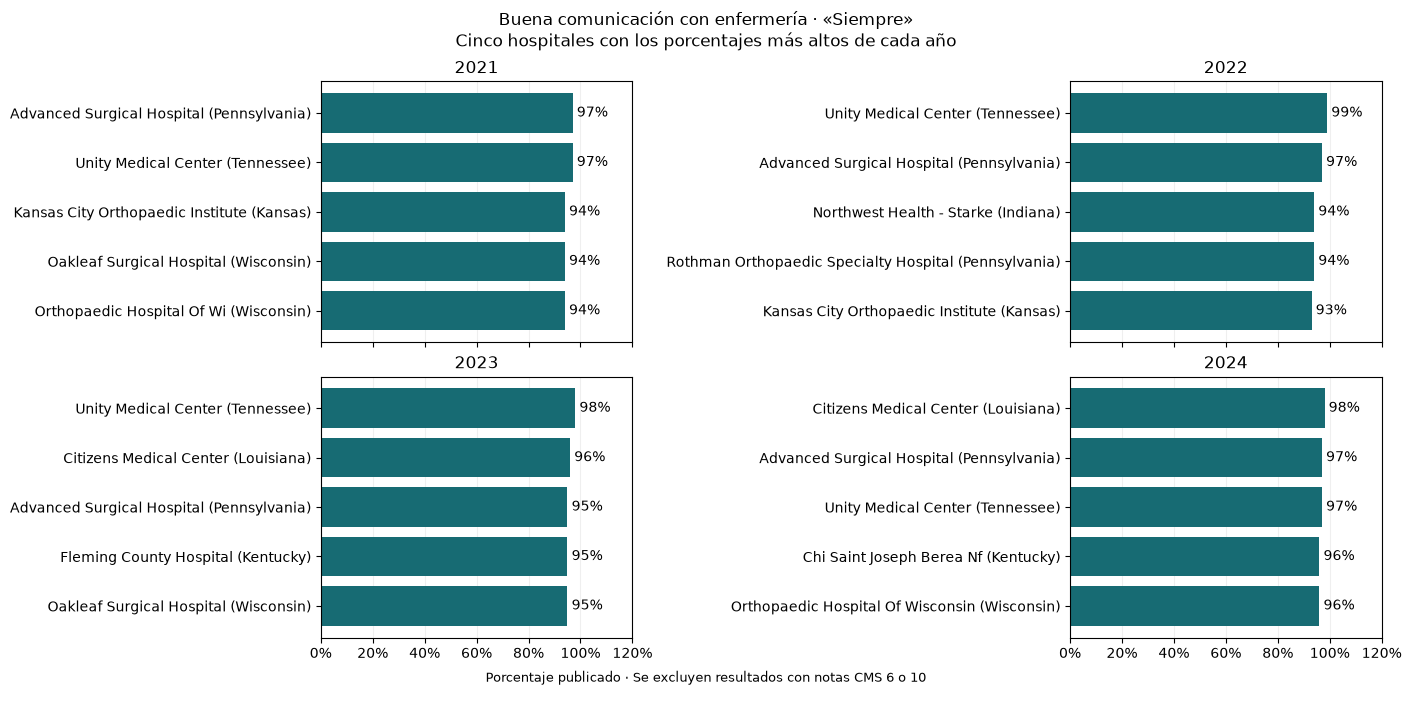

In [14]:
anios = [2021, 2022, 2023, 2024]

top_anual = (
    hcahps.loc[
        hcahps["HCAHPS Measure ID"].eq("H_COMP_1_A_P")
        & hcahps["Start Date"].dt.year.isin(anios)
        & ~hcahps["HCAHPS Answer Percent Footnote"].str.contains(
            r"(?:^|,)\s*(?:6|10)\s*(?:,|$)", na=False
        ),
        ["Facility ID", "Facility Name", "State", "Start Date", "Valor"],
    ]
    .dropna(subset=["Valor"])
    .assign(Anio=lambda df: df["Start Date"].dt.year)
    .sort_values(["Valor", "Facility Name", "Facility ID"],
                 ascending=[False, True, True])
    .groupby("Anio").head(5)
)

fig, ejes = plt.subplots(2, 2, figsize=(14, 7), sharex=True, layout="constrained")

for ax, anio_panel in zip(ejes.flat, anios):
    top = top_anual.loc[top_anual["Anio"].eq(anio_panel)]
    estados = top["State"].map(nombres_estados).fillna(top["State"])
    etiquetas = top["Facility Name"].str.title() + " (" + estados + ")"

    barras = ax.barh(range(len(top)), top["Valor"].astype(float), color="#176B73")
    ax.set_yticks(range(len(top)), etiquetas)
    ax.invert_yaxis()
    ax.bar_label(barras, fmt="%.0f%%", padding=3)
    ax.set(title=str(anio_panel), xlim=(0, 120))
    ax.xaxis.set_major_formatter(PercentFormatter(100))
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    "Buena comunicación con enfermería · «Siempre»\n"
    "Cinco hospitales con los porcentajes más altos de cada año"
)
fig.supxlabel(
    "Porcentaje publicado · Se excluyen resultados con notas CMS 6 o 10\n",
    fontsize=9,
)
plt.show()

### 2. ¿Dónde reportan los pacientes más y menos frecuencia de trato cortés y respetuoso por parte de enfermería?

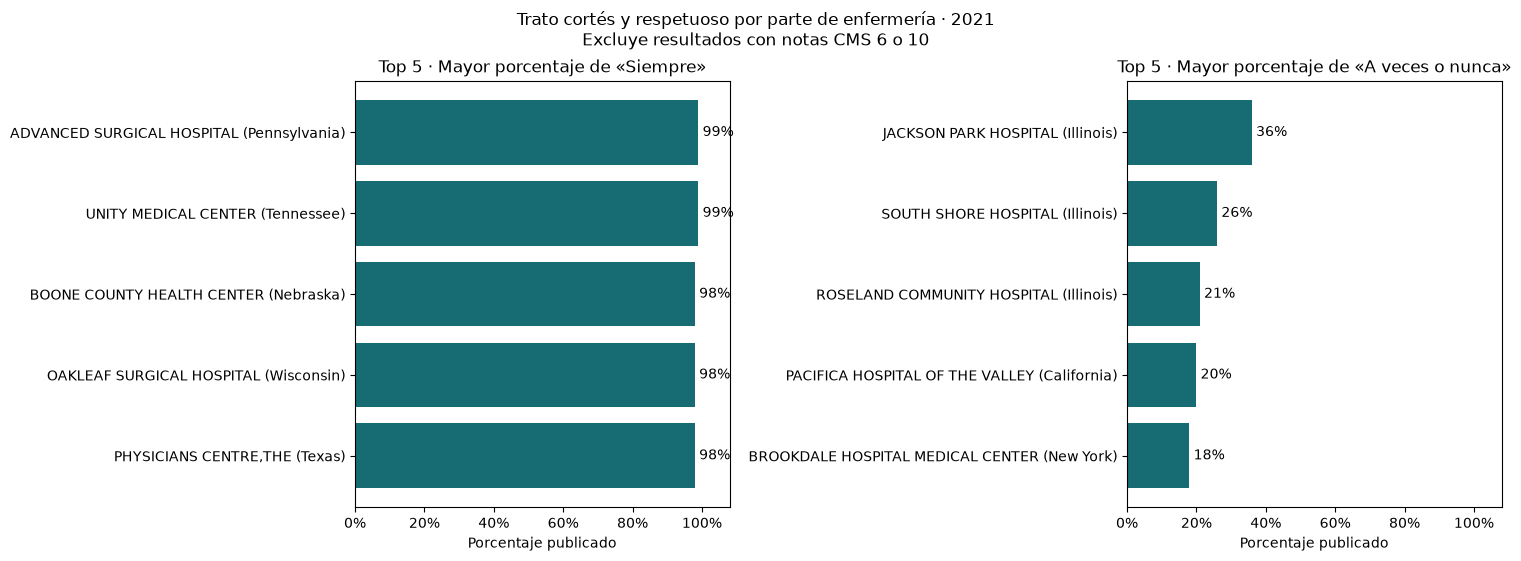

In [15]:
graficar_extremos(
    ["H_NURSE_RESPECT_A_P", "H_NURSE_RESPECT_SN_P"],
    ["Mayor porcentaje de «Siempre»", "Mayor porcentaje de «A veces o nunca»"],
    "Trato cortés y respetuoso por parte de enfermería",
)

### 3. ¿Dónde se reporta ayuda a tiempo con mayor y menor frecuencia?

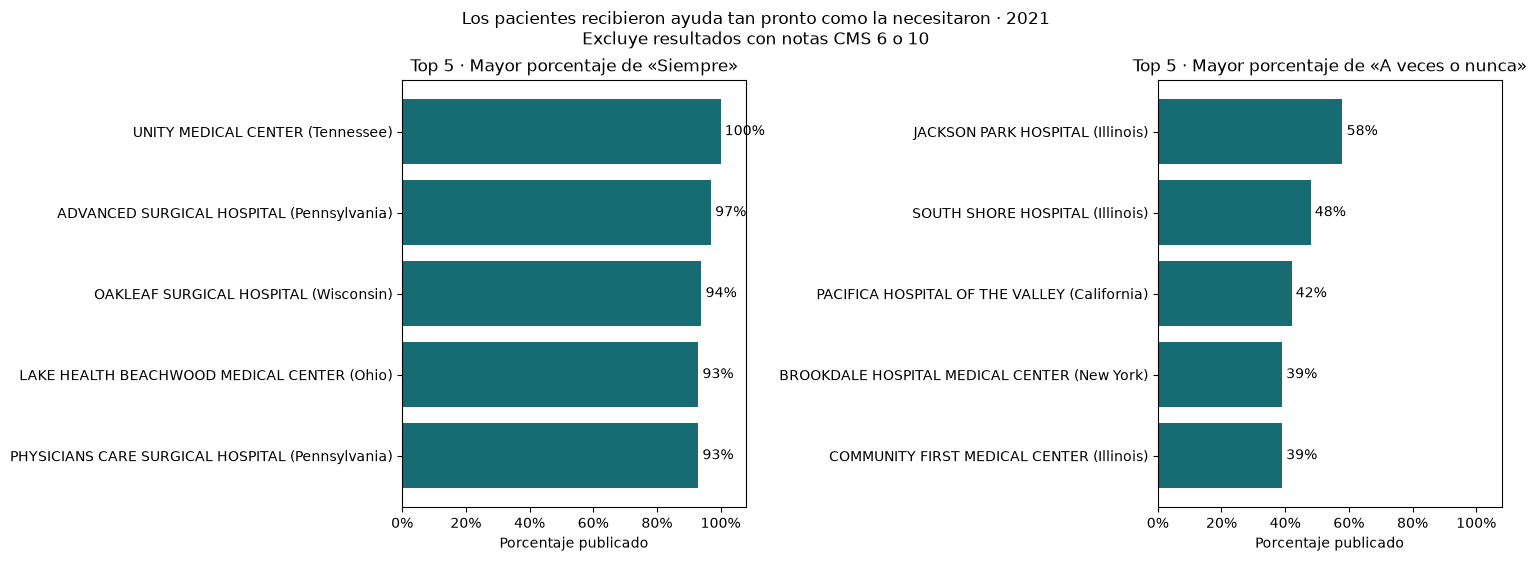

In [16]:
graficar_extremos(
    ["H_COMP_3_A_P", "H_COMP_3_SN_P"],
    ["Mayor porcentaje de «Siempre»", "Mayor porcentaje de «A veces o nunca»"],
    "Los pacientes recibieron ayuda tan pronto como la necesitaron",
)

### 4. ¿Cómo se distribuyen las estrellas de rapidez de respuesta por estado?

La barra resume los hospitales con calificación publicada. Los estados y territorios se ordenan por la proporción de hospitales con 4 o 5 estrellas. La tabla debajo incluye también los hospitales sin calificación, incluso donde no hay resultados publicados.

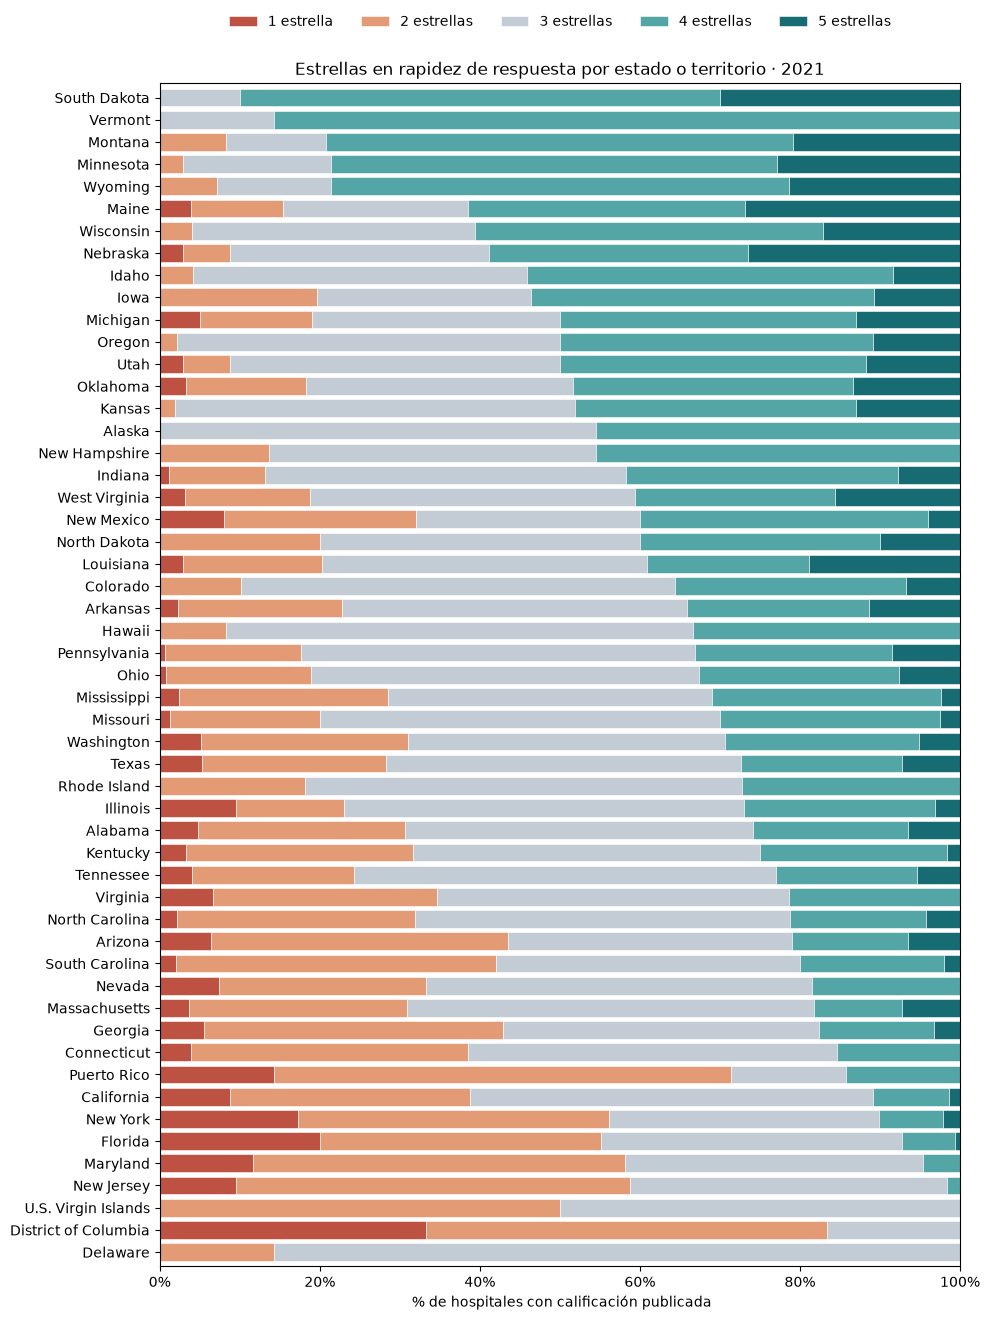

H_COMP_3_STAR_RATING,1,2,3,4,5,Sin calificación
State,,,,,,
Alabama,3,16,27,12,4,30
Alaska,0,0,6,5,0,12
American Samoa,0,0,0,0,0,1
Arizona,4,23,22,9,4,21
Arkansas,1,9,19,10,5,34
California,26,88,148,28,4,47
Colorado,0,6,32,17,4,28
Connecticut,1,9,12,4,0,5
Delaware,0,1,6,0,0,1


In [17]:
codigo_estrellas = "H_COMP_3_STAR_RATING"
estrellas_por_estado = tabla_hospitales.loc[
    tabla_hospitales["Periodo"].eq(periodo_grafico), ["State", codigo_estrellas]
].copy()
estrellas_por_estado["State"] = estrellas_por_estado["State"].replace(nombres_estados)
conteo_estrellas = (
    pd.crosstab(estrellas_por_estado["State"], estrellas_por_estado[codigo_estrellas])
    .reindex(columns=range(1, 6), fill_value=0)
    .sort_index()
)
distribucion = conteo_estrellas.div(conteo_estrellas.sum(axis=1), axis=0).mul(100)
orden = (distribucion[4] + distribucion[5]).sort_values().index

ax = distribucion.loc[orden].plot.barh(
    stacked=True, figsize=(10, max(5, len(orden) * 0.25)), width=0.8,
    color=["#BD5142", "#E29B75", "#C3CCD5", "#54A6A6", "#176B73"], edgecolor="white", linewidth=0.4
)

ax.set(xlim=(0, 100), xlabel=" % de hospitales con calificación publicada", ylabel="",
       title=f"Estrellas en rapidez de respuesta por estado o territorio · {anio}")
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.legend(["1 estrella", "2 estrellas", "3 estrellas", "4 estrellas", "5 estrellas"],
          ncol=5, loc="lower center", bbox_to_anchor=(0.5, 1.035), frameon=False)
plt.tight_layout()
plt.show()

display(
    conteo_estrellas.reindex(estrellas_por_estado.groupby("State").size().index, fill_value=0)
    .assign(**{"Sin calificación": estrellas_por_estado.groupby("State")[codigo_estrellas]
               .apply(lambda valores: valores.isna().sum())})
)

## Visualizaciones finales

1. ¿Cómo evoluciona la buena (y mala) comunicación de enfermería de todos los hospitales que permanecen en la encuesta todos los años (2021 al 2024)? El siguiente gráfico conserva los hospitales con ambos resultados a lo largo de los 4 años y toma las muestras pequeñas también. Las dos barras no suman 100 % porque también existe la respuesta «Normalmente».

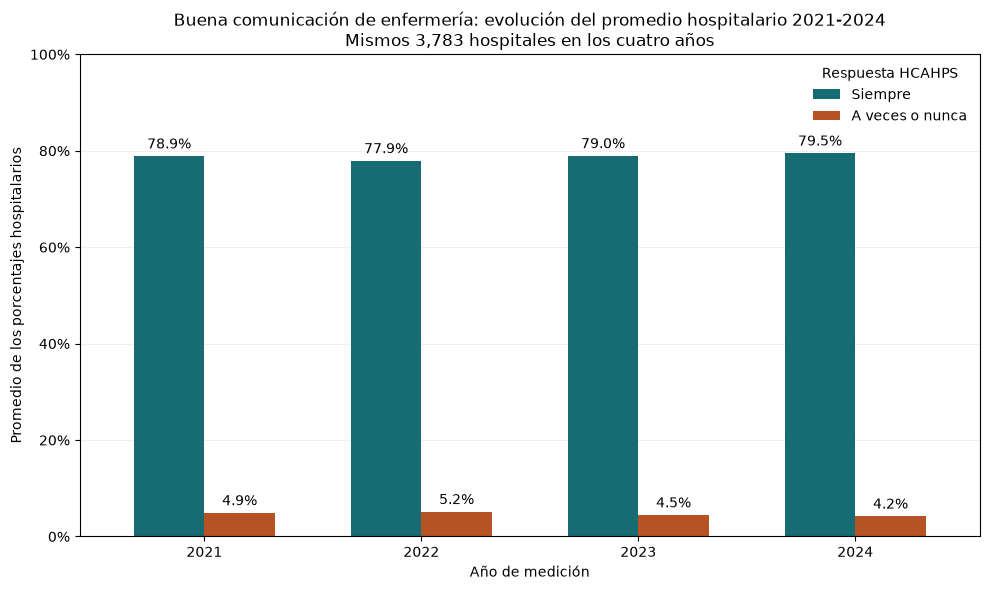

,Siempre,A veces o nunca
Anio,,
2021,78.92,4.93
2022,77.95,5.17
2023,78.99,4.48
2024,79.53,4.23


In [18]:
respuestas = {
    "H_COMP_1_A_P": "Siempre",
    "H_COMP_1_SN_P": "A veces o nunca",
}
anios = [2021, 2022, 2023, 2024]

enfermeria = (
    tabla_hospitales[["Facility ID", "Periodo", *respuestas]]
    .assign(Anio=lambda df: df["Periodo"].array.left.year)
    .loc[lambda df: df["Anio"].isin(anios)]
    .dropna(subset=list(respuestas))
)
enfermeria = enfermeria.loc[
    enfermeria.groupby("Facility ID")["Anio"].transform("nunique").eq(len(anios))
]

promedios = (
    enfermeria.groupby("Anio")[list(respuestas)].mean()
    .reindex(anios)
    .rename(columns=respuestas)
)
n_hospitales = enfermeria["Facility ID"].nunique()

ax = promedios.plot.bar(
    figsize=(10, 6), color=["#176B73", "#B65325"], width=0.65, rot=0,
)

for barras in ax.containers:
    ax.bar_label(barras, fmt="%.1f%%", padding=3)

ax.set(
    title=f"Buena comunicación de enfermería: evolución del promedio hospitalario 2021-2024\n"
          f"Mismos {n_hospitales:,} hospitales en los cuatro años",
    xlabel="Año de medición",
    ylabel="Promedio de los porcentajes hospitalarios",
    ylim=(0, 100),
)
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.legend(title="Respuesta HCAHPS", frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

display(promedios.round(2))

*Promedio simple de porcentajes hospitalarios. Mismos 3.783 hospitales con ambos resultados disponibles en los cuatro años. Incluye resultados con notas CMS. La categoría «Normalmente» no se representa.*

2. ¿Qué hospitales tienen "siempre" buena comunicación de enfermería a lo largo de estos años?

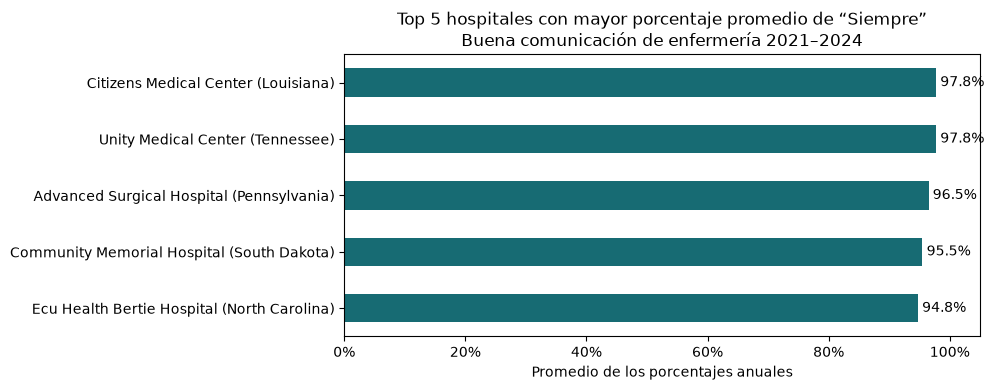

In [19]:
promedio_hospital = (
    enfermeria.groupby("Facility ID")[["H_COMP_1_A_P", "H_COMP_1_SN_P"]].mean()
    .join(
        tabla_hospitales.loc[
            tabla_hospitales["Periodo"].array.left.year == 2024,
            ["Facility ID", "Facility Name", "State"],
        ].set_index("Facility ID")
    )
    .assign(Hospital=lambda df: df["Facility Name"].str.title()
            + " (" + df["State"].replace(nombres_estados) + ")")
)

top = promedio_hospital.sort_values(
    ["H_COMP_1_A_P", "Facility Name"], ascending=[False, True]
).head(5)

ax = top.plot.barh(
    x="Hospital", y="H_COMP_1_A_P",
    figsize=(10, 4), color="#176B73", legend=False,
)
ax.invert_yaxis()
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set(
    title="Top 5 hospitales con mayor porcentaje promedio de “Siempre”\n"
          "Buena comunicación de enfermería 2021–2024",
    xlabel="Promedio de los porcentajes anuales",
    ylabel="", xlim=(0, 105), xticks=range(0, 101, 20),
)
ax.xaxis.set_major_formatter(PercentFormatter(100))
plt.tight_layout()
plt.show()

3. ¿Qué hospitales tienen "peor" comunicación de enfermería todos estos años?

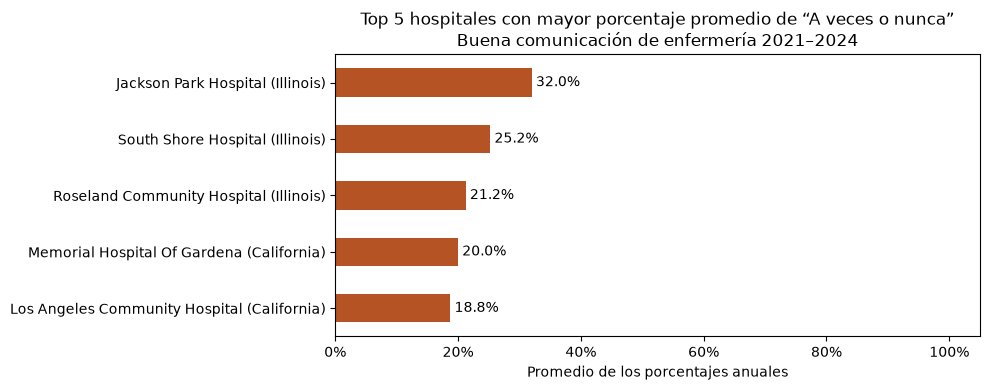

In [20]:
top = promedio_hospital.sort_values(
    ["H_COMP_1_SN_P", "Facility Name"], ascending=[False, True]
).head(5)

ax = top.plot.barh(
    x="Hospital", y="H_COMP_1_SN_P",
    figsize=(10, 4), color="#B65325", legend=False,
)
ax.invert_yaxis()
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set(
    title="Top 5 hospitales con mayor porcentaje promedio de “A veces o nunca”\n"
          "Buena comunicación de enfermería 2021–2024",
    xlabel="Promedio de los porcentajes anuales",
    ylabel="", xlim=(0, 105), xticks=range(0, 101, 20),
)
ax.xaxis.set_major_formatter(PercentFormatter(100))
plt.tight_layout()
plt.show()

4. Proporción de estrellas en rapidez de respuesta por estado.

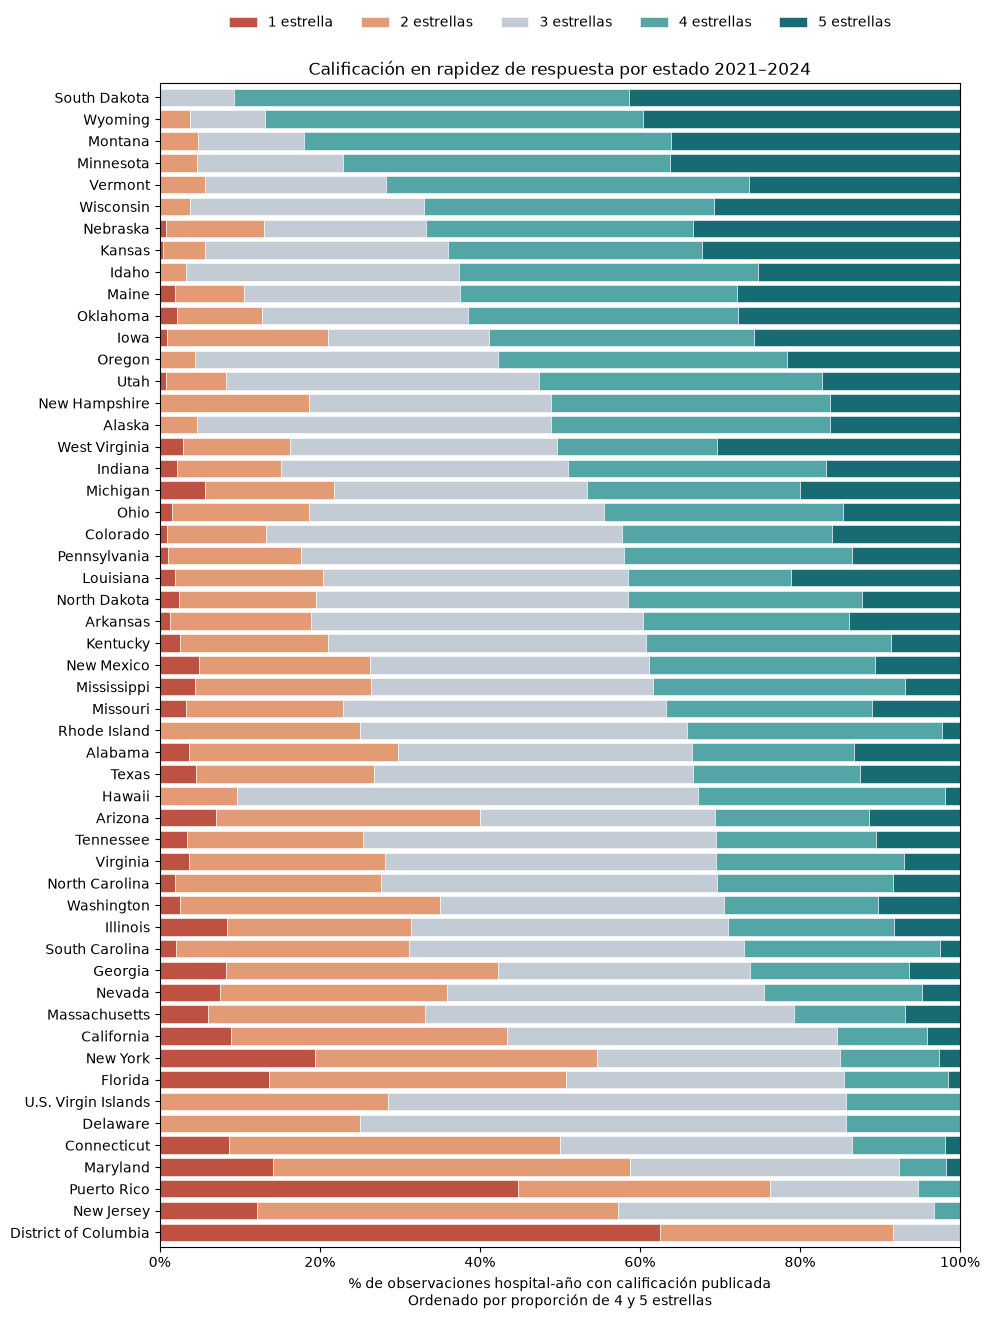

Estrellas,1,2,3,4,5,Total
State,,,,,,
Alabama,9,63,89,49,32,242
Alaska,0,2,19,15,7,43
Arizona,18,84,75,49,29,255
Arkansas,2,28,66,41,22,159
California,103,398,476,129,48,1154
Colorado,2,28,100,59,36,225
Connecticut,9,43,38,12,2,104
Delaware,0,7,17,4,0,28
District of Columbia,15,7,2,0,0,24


In [21]:
estrellas_por_estado = (
    tabla_hospitales.loc[
        tabla_hospitales["Periodo"].array.left.year.isin([2021, 2022, 2023, 2024])
        & tabla_hospitales["H_COMP_3_STAR_RATING"].isin([1, 2, 3, 4, 5]),
        ["State", "H_COMP_3_STAR_RATING"],
    ]
    .replace({"State": nombres_estados})
)

conteo_estrellas = (
    pd.crosstab(
        estrellas_por_estado["State"],
        estrellas_por_estado["H_COMP_3_STAR_RATING"],
    )
    .reindex(columns=range(1, 6), fill_value=0)
    .sort_index()
)

distribucion = conteo_estrellas.div(conteo_estrellas.sum(axis=1), axis=0).mul(100)
orden = (distribucion[4] + distribucion[5]).sort_values().index

ax = distribucion.loc[orden].plot.barh(
    stacked=True,
    figsize=(10, max(5, len(orden) * 0.25)),
    width=0.8,
    color=["#BD5142", "#E29B75", "#C3CCD5", "#54A6A6", "#176B73"],
    edgecolor="white",
    linewidth=0.4,
)
ax.set(
    xlim=(0, 100),
    xlabel="% de observaciones hospital-año con calificación publicada\n"
    "Ordenado por proporción de 4 y 5 estrellas",
    ylabel="",
    title="\nCalificación en rapidez de respuesta por estado 2021–2024",
)
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.legend(
    ["1 estrella", "2 estrellas", "3 estrellas", "4 estrellas", "5 estrellas"],
    ncol=5, loc="lower center", bbox_to_anchor=(0.5, 1.035), frameon=False,
)
plt.tight_layout()
plt.show()

# Conteos acumulados que sustentan los porcentajes del gráfico.
display(conteo_estrellas.rename_axis(columns="Estrellas").assign(
    Total=conteo_estrellas.sum(axis=1)
))

   - En Hawaii y Delaware predominan las 3 estrellas, especialmente en Delaware. “Predomina una calificación intermedia” sería más preciso.
   - District of Columbia y Puerto Rico concentran una proporción elevada de calificaciones de 1 y 2 estrellas. En District of Columbia predominan las de 1 estrella. Puerto Rico presenta una distribución más repartida.
   - New York también destaca por su proporción de calificaciones bajas. Visualmente, más de la mitad de sus observaciones corresponden a 1 o 2 estrellas.
   - Entre 2021 y 2024, South Dakota, Wyoming y Montana registraron las mayores proporciones de observaciones con 4 o 5 estrellas en rapidez de respuesta del personal. En Hawaii y Delaware predominaron las calificaciones de 3 estrellas. District of Columbia y Puerto Rico concentraron una elevada proporción de calificaciones de 1 y 2 estrellas, un patrón que también merece atención en New York. El análisis incluye únicamente las observaciones con calificación publicada.

5. Selección de 6 estados con "peor" porcentaje de la ayuda a tiempo.

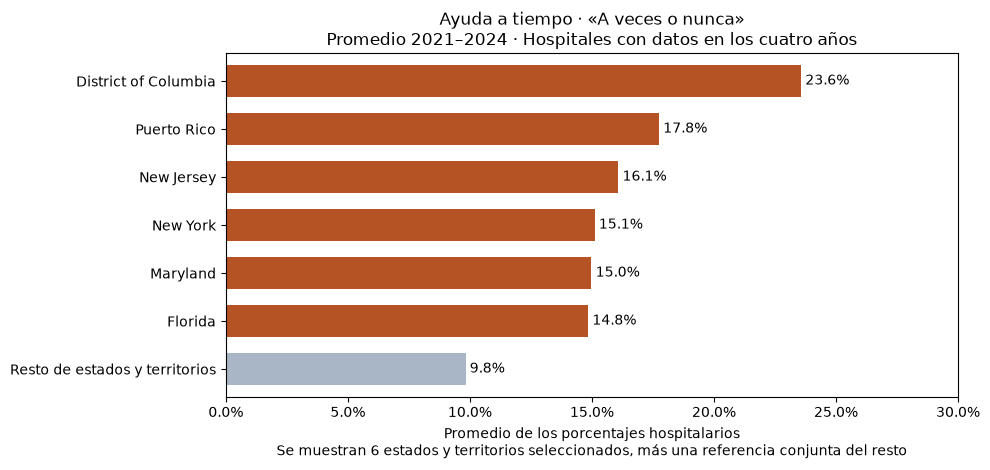

In [22]:
estados_zoom = ["DC", "PR", "NY", "MD", "NJ", "FL"]

ayuda_comparacion = (
    tabla_hospitales[["Facility ID", "State", "Periodo", "H_COMP_3_SN_P"]]
    .assign(Anio=lambda df: df["Periodo"].array.left.year)
    .loc[lambda df: df["Anio"].isin([2021, 2022, 2023, 2024])]
    .dropna(subset=["H_COMP_3_SN_P"])
)
ayuda_comparacion = ayuda_comparacion.loc[
    ayuda_comparacion.groupby("Facility ID")["Anio"]
    .transform("nunique").eq(4)
]

comparacion = pd.concat([
    ayuda_comparacion.loc[ayuda_comparacion["State"].isin(estados_zoom)]
    .groupby("State")["H_COMP_3_SN_P"].mean()
    .rename(index=nombres_estados),

    pd.Series({
        "Resto de estados y territorios":
            ayuda_comparacion.loc[
                ~ayuda_comparacion["State"].isin(estados_zoom),
                "H_COMP_3_SN_P",
            ].mean()
    }),
]).sort_values(ascending=False)

ax = comparacion.plot.barh(
    figsize=(10, 4.8),
    color=[
        "#A8B6C5" if nombre == "Resto de estados y territorios" else "#B65325"
        for nombre in comparacion.index
    ],
    width=0.65,
)
ax.invert_yaxis()
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set(
    title="Ayuda a tiempo · «A veces o nunca»\n"
          "Promedio 2021–2024 · Hospitales con datos en los cuatro años",
    xlabel="Promedio de los porcentajes hospitalarios\n"
    "Se muestran 6 estados y territorios seleccionados, más una referencia conjunta del resto",
    ylabel="", xlim=(0, 30),
)
ax.xaxis.set_major_formatter(PercentFormatter(100))
plt.tight_layout()
plt.show()

6. Top 10 hospitales menos recomendados y top 10 más recomendados.

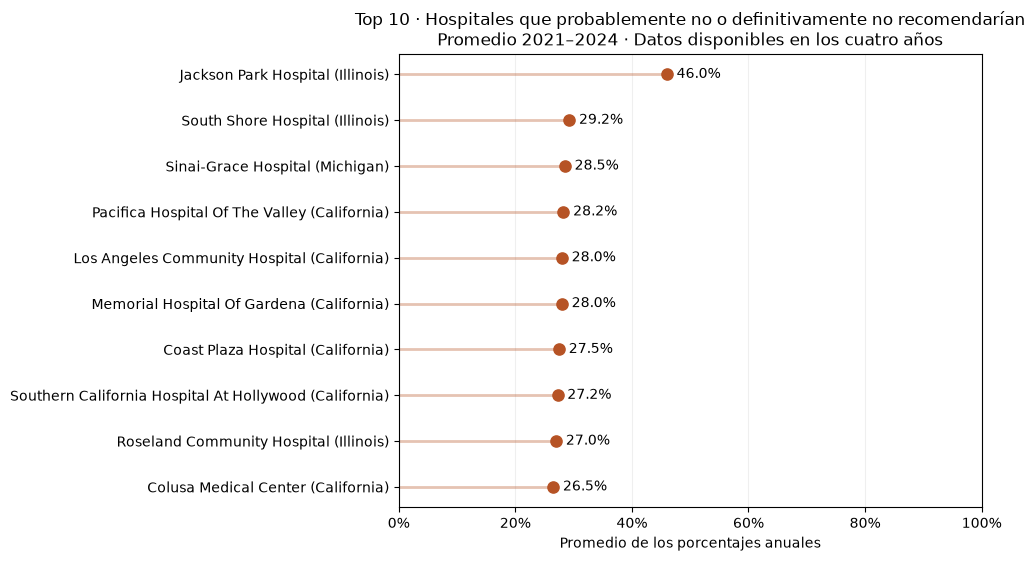

In [23]:
recomendacion = (
    tabla_hospitales[["Facility ID", "Periodo", "H_RECMND_DN"]]
    .assign(Anio=lambda df: df["Periodo"].array.left.year)
    .loc[lambda df: df["Anio"].isin([2021, 2022, 2023, 2024])]
    .dropna(subset=["H_RECMND_DN"])
)
recomendacion = recomendacion.loc[
    recomendacion.groupby("Facility ID")["Anio"].transform("nunique").eq(4)
]

top_no_recomendados = (
    recomendacion.groupby("Facility ID")[["H_RECMND_DN"]].mean()
    .join(
        tabla_hospitales.loc[
            tabla_hospitales["Periodo"].array.left.year == 2024,
            ["Facility ID", "Facility Name", "State"],
        ].set_index("Facility ID")
    )
    .sort_values(["H_RECMND_DN", "Facility Name"], ascending=[False, True])
    .head(10)
    .assign(Hospital=lambda df: df["Facility Name"].str.title()
            + " (" + df["State"].replace(nombres_estados) + ")")
)

fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")

ax.hlines(
    y=range(len(top_no_recomendados)),
    xmin=0, xmax=top_no_recomendados["H_RECMND_DN"].astype(float),
    color="#B65325", alpha=0.35, linewidth=2,
)
ax.scatter(
    top_no_recomendados["H_RECMND_DN"].astype(float),
    range(len(top_no_recomendados)),
    color="#B65325", s=65,
)

for posicion, valor in enumerate(top_no_recomendados["H_RECMND_DN"]):
    ax.annotate(f"{valor:.1f}%", (valor, posicion),
                xytext=(7, 0), textcoords="offset points", va="center")

ax.set_yticks(range(len(top_no_recomendados)), top_no_recomendados["Hospital"])
ax.invert_yaxis()
ax.set(
    title="Top 10 · Hospitales que ""probablemente no o definitivamente no"" recomendarían\n"
          "Promedio 2021–2024 · Datos disponibles en los cuatro años",
    xlabel="Promedio de los porcentajes anuales",
    xlim=(0, 100),
)
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
plt.show()

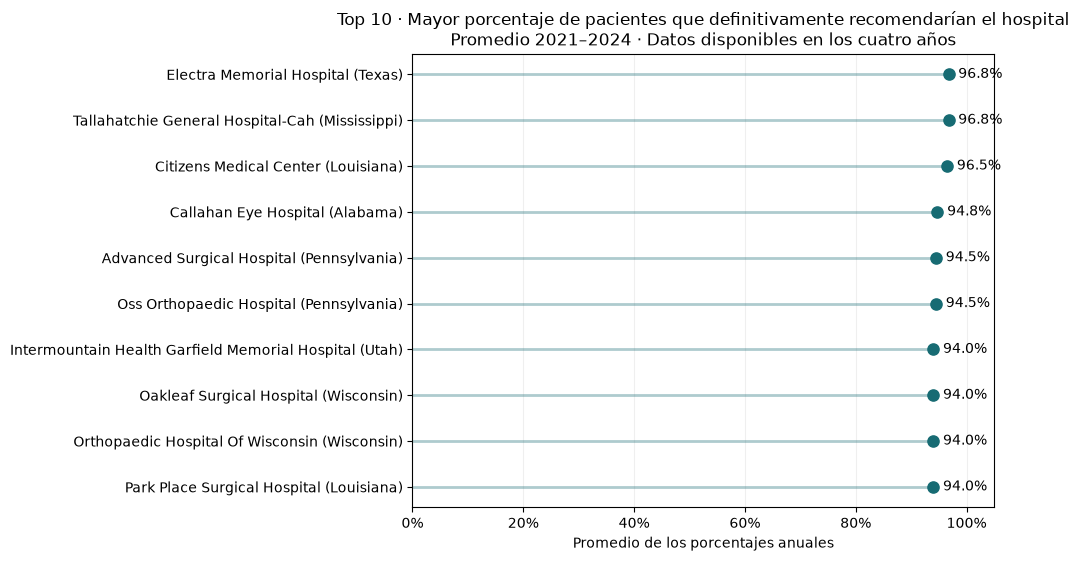

In [24]:
recomendacion_positiva = (
    tabla_hospitales[["Facility ID", "Periodo", "H_RECMND_DY"]]
    .assign(Anio=lambda df: df["Periodo"].array.left.year)
    .loc[lambda df: df["Anio"].isin([2021, 2022, 2023, 2024])]
    .dropna(subset=["H_RECMND_DY"])
)
recomendacion_positiva = recomendacion_positiva.loc[
    recomendacion_positiva.groupby("Facility ID")["Anio"]
    .transform("nunique").eq(4)
]

top_recomendados = (
    recomendacion_positiva.groupby("Facility ID")[["H_RECMND_DY"]].mean()
    .join(
        tabla_hospitales.loc[
            tabla_hospitales["Periodo"].array.left.year == 2024,
            ["Facility ID", "Facility Name", "State"],
        ].set_index("Facility ID")
    )
    .sort_values(["H_RECMND_DY", "Facility Name"], ascending=[False, True])
    .head(10)
    .assign(Hospital=lambda df: df["Facility Name"].str.title()
            + " (" + df["State"].replace(nombres_estados) + ")")
)

fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")

ax.hlines(
    y=range(len(top_recomendados)),
    xmin=0, xmax=top_recomendados["H_RECMND_DY"].astype(float),
    color="#176B73", alpha=0.35, linewidth=2,
)
ax.scatter(
    top_recomendados["H_RECMND_DY"].astype(float),
    range(len(top_recomendados)),
    color="#176B73", s=65,
)

for posicion, valor in enumerate(top_recomendados["H_RECMND_DY"]):
    ax.annotate(
        f"{valor:.1f}%", (valor, posicion),
        xytext=(7, 0), textcoords="offset points", va="center",
    )

ax.set_yticks(range(len(top_recomendados)), top_recomendados["Hospital"])
ax.invert_yaxis()
ax.set(
    title="Top 10 · Mayor porcentaje de pacientes que definitivamente recomendarían el hospital\n"
          "Promedio 2021–2024 · Datos disponibles en los cuatro años",
    xlabel="Promedio de los porcentajes anuales",
    xlim=(0, 105), xticks=range(0, 101, 20),
)
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
plt.show()